In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [8]:
file1 = pd.read_csv(r"C:\Users\Niharika\Downloads\Retail_Analysis2009-10.csv")
file1

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom,20.34
...,...,...,...,...,...,...,...,...,...
536637,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,09-12-2011 12:50,2.10,12680.0,France,12.60
536638,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,09-12-2011 12:50,4.15,12680.0,France,16.60
536639,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,09-12-2011 12:50,4.15,12680.0,France,16.60
536640,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,09-12-2011 12:50,4.95,12680.0,France,14.85


In [9]:
file2 = pd.read_csv(r"C:\Users\Niharika\Downloads\Retail_Analysis2010-11.csv")

In [15]:
print("Shape of 2009-2010 : " , file1.shape)
print("Shape of 2010-2011 : " , file2.shape)

Shape of 2009-2010 :  (536642, 9)
Shape of 2010-2011 :  (518596, 9)


In [17]:
df = pd.concat([file1 , file2] , ignore_index=True)

In [20]:
df.shape

(1055238, 9)

In [21]:
df.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country', 'Revenue'],
      dtype='object')

In [23]:
df.dtypes

Invoice         object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
Price          float64
Customer ID    float64
Country         object
Revenue        float64
dtype: object

In [24]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom,20.34


In [25]:
df['InvoiceDate'] = pd.to_datetime(
                    df['InvoiceDate'],
                    dayfirst=True ,
                    errors = "coerce"
)

In [28]:
df.dtypes

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
Revenue               float64
dtype: object

In [29]:
df.isna().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    242870
Country             0
Revenue             0
dtype: int64

In [30]:
df.duplicated().sum()

np.int64(22202)

In [32]:
print("Duplicates in first dataset :" , file1.duplicated().sum())
print("Duplicates in second dataset :" , file2.duplicated().sum())

print("Rows in first dataset:" , len(file1))
print("Rows in second dataset:" , len(file2))
print("Rows in combined dataset:",len(df))


Duplicates in first dataset : 0
Duplicates in second dataset : 0
Rows in first dataset: 536642
Rows in second dataset: 518596
Rows in combined dataset: 1055238


In [34]:
overlap = file1.merge(file2,
                      how='inner')
print("Identical rows present in both file :" , len(overlap))

Identical rows present in both file : 22202


In [35]:
print("first dataset")
print(file1['InvoiceDate'].min(),'to' , file1['InvoiceDate'].max())

print("second dataset")
print(file2['InvoiceDate'].min(), 'to' , file2['InvoiceDate'].max())

first dataset
01-02-2011 08:23 to 31-10-2011 17:19
second dataset
01-02-2010 08:13 to 31-10-2010 16:26


In [37]:
file1[['Invoice' , 'StockCode' , 'Description' , 'InvoiceDate']].head()

,Invoice,StockCode,Description,InvoiceDate
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,01-12-2010 08:26
1,536365,71053,WHITE METAL LANTERN,01-12-2010 08:26
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,01-12-2010 08:26
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,01-12-2010 08:26
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,01-12-2010 08:26


In [38]:
file2[['Invoice' , 'StockCode' , 'Description' , 'InvoiceDate']].head()

,Invoice,StockCode,Description,InvoiceDate
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,01-12-2009 07:45
1,489434,79323P,PINK CHERRY LIGHTS,01-12-2009 07:45
2,489434,79323W,WHITE CHERRY LIGHTS,01-12-2009 07:45
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",01-12-2009 07:45
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,01-12-2009 07:45


In [39]:
overlap[['Invoice' , 'StockCode' , 'Description' , 'InvoiceDate']].head()

,Invoice,StockCode,Description,InvoiceDate
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,01-12-2010 08:26
1,536365,71053,WHITE METAL LANTERN,01-12-2010 08:26
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,01-12-2010 08:26
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,01-12-2010 08:26
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,01-12-2010 08:26


In [42]:
common_invoice = set(file1['Invoice']) & set(file2['Invoice'])

In [44]:
print("Invoice numbers present in both dataset :" , len(common_invoice))

Invoice numbers present in both dataset : 1088


In [47]:
total_revenue = df['Revenue'].sum()
total_revenue

np.float64(19231800.518)

In [48]:
total_quantity = df['Quantity'].sum()
total_quantity

np.int64(10575687)

In [51]:
unique_invoices= df['Invoice'].nunique()
unique_invoices

53628

In [53]:
unique_products = df['StockCode'].nunique()
unique_products

5305

In [55]:
unique_countries = df['Country'].nunique()
unique_countries

43

In [57]:
unique_cust_id = df['Customer ID'].nunique()
unique_cust_id

5942

In [60]:
df['YearMonth'] =  df['InvoiceDate'].dt.to_period('M')

In [65]:
monthly_revenue = (df.groupby('YearMonth', as_index=False)['Revenue'].sum())
monthly_revenue['YearMonth'] = (monthly_revenue['YearMonth'].astype(str))

In [66]:
print(monthly_revenue.head(10))

  YearMonth     Revenue
0   2009-12  796648.500
1   2010-01  622479.502
2   2010-02  531265.366
3   2010-03  763247.241
4   2010-04  587926.692
5   2010-05  613270.720
6   2010-06  677073.870
7   2010-07  573333.690
8   2010-08  654774.390
9   2010-09  851105.961


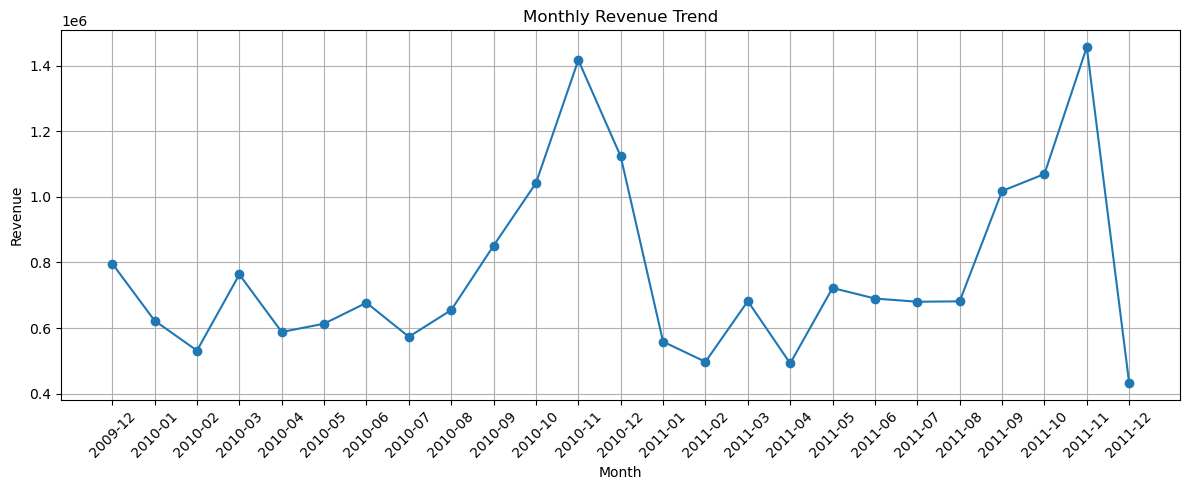

In [74]:
plt.figure(figsize=(12,5))

plt.plot(
    monthly_revenue['YearMonth'],
    monthly_revenue['Revenue'] ,
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [77]:
top_products = (df.groupby('Description', as_index=False)['Revenue'].
                sum()
                .sort_values('Revenue' , ascending=False)
                .head(10)
)

print(top_products)

                              Description    Revenue
3915             REGENCY CAKESTAND 3 TIER  327345.20
1472                       DOTCOM POSTAGE  322647.47
5266   WHITE HANGING HEART T-LIGHT HOLDER  257192.70
2508              JUMBO BAG RED RETROSPOT  148505.35
3294                        PARTY BUNTING  147870.80
328         ASSORTED COLOUR BIRD ORNAMENT  131043.74
3261      PAPER CHAIN KIT 50'S CHRISTMAS   121523.49
3689                              POSTAGE  112341.00
1059                        CHILLI LIGHTS   84521.81
4061  ROTATING SILVER ANGELS T-LIGHT HLDR   73745.87


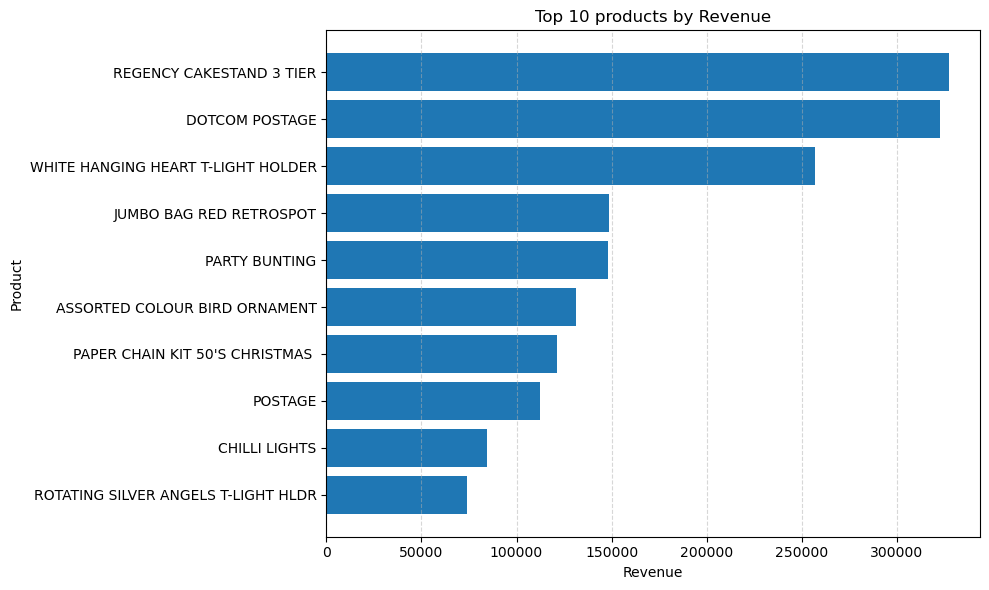

In [86]:
plt.figure(figsize=(10,6))

plt.barh(
    top_products['Description'],
    top_products['Revenue']
)

plt.title('Top 10 products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product')
plt.gca().invert_yaxis()
plt.grid(axis='x' , linestyle='--' ,alpha=0.5)
plt.tight_layout()
plt.show()

In [84]:
country_revenue = (df.groupby('Country' , as_index=False)['Revenue'].sum().sort_values('Revenue' , ascending=False).head(10)
)

print(country_revenue)

           Country       Revenue
40  United Kingdom  1.632882e+07
11            EIRE  6.152291e+05
26     Netherlands  5.485233e+05
15         Germany  4.174299e+05
14          France  3.279967e+05
0        Australia  1.670616e+05
36     Switzerland  9.970646e+04
34           Spain  9.180816e+04
35          Sweden  8.777552e+04
10         Denmark  6.574109e+04


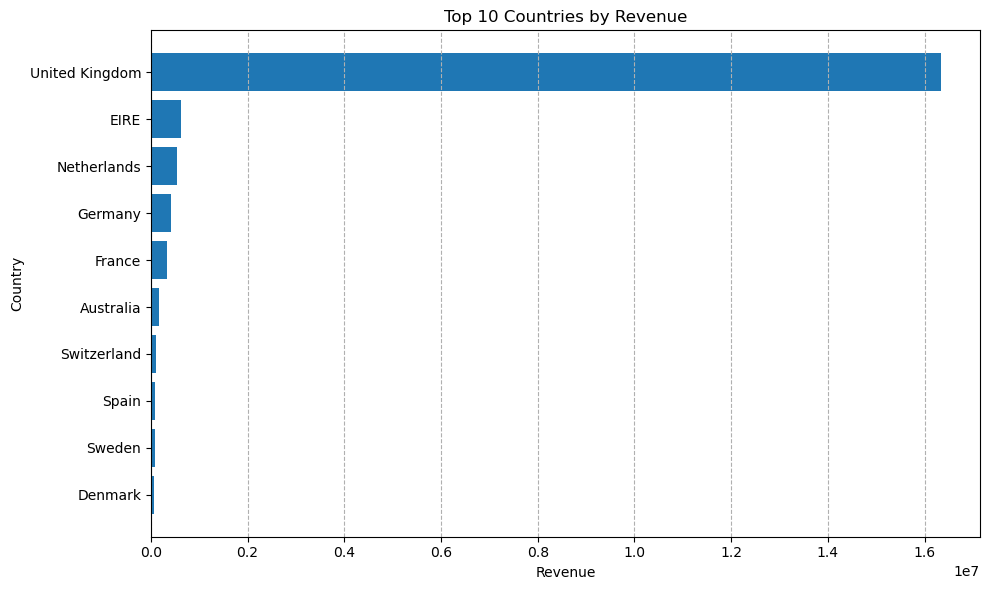

In [96]:
plt.figure(figsize=(10,6))

plt.barh(
    country_revenue['Country'],
    country_revenue['Revenue']
)

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Country')

plt.gca().invert_yaxis()
plt.grid(axis='x',linestyle ='--')

plt.tight_layout()
plt.show()

In [97]:
monthly_revenue['Revenue_Growth_%'] = (
    monthly_revenue['Revenue'].pct_change()*100
)

print(monthly_revenue.head(10))

  YearMonth     Revenue  Revenue_Growth_%
0   2009-12  796648.500               NaN
1   2010-01  622479.502        -21.862716
2   2010-02  531265.366        -14.653356
3   2010-03  763247.241         43.665913
4   2010-04  587926.692        -22.970348
5   2010-05  613270.720          4.310746
6   2010-06  677073.870         10.403750
7   2010-07  573333.690        -15.321841
8   2010-08  654774.390         14.204764
9   2010-09  851105.961         29.984614


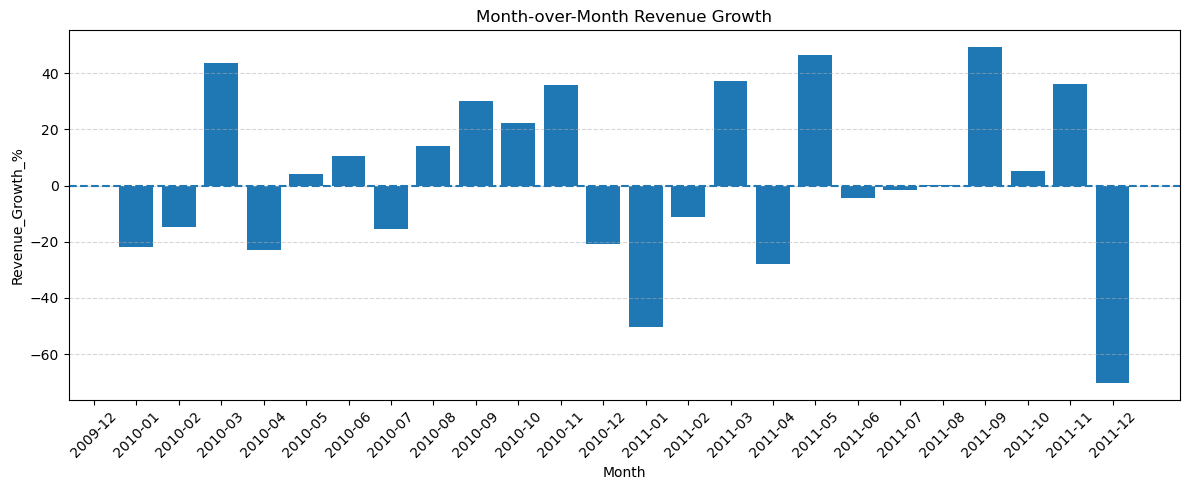

In [100]:
plt.figure(figsize=(12,5))

plt.bar(
    monthly_revenue['YearMonth'],
    monthly_revenue['Revenue_Growth_%']
)

plt.title('Month-over-Month Revenue Growth')
plt.xlabel('Month')
plt.ylabel('Revenue_Growth_%')
plt.axhline(y=0 , linestyle='--')
plt.xticks(rotation=45)
plt.grid(axis='y',linestyle='--' , alpha=0.5)
plt.tight_layout()
plt.show()

In [102]:
customer_revenue = (
    df.dropna(subset=['Customer ID'])
    .groupby('Customer ID' , as_index=False)['Revenue']
    .sum()
    .sort_values('Revenue' , ascending=False)
    .head(10)
)

print(customer_revenue)

      Customer ID    Revenue
5756      18102.0  598215.22
2300      14646.0  523342.07
1810      14156.0  296378.14
2565      14911.0  270169.49
5104      17450.0  233419.39
1348      13694.0  190862.96
5165      17511.0  171885.98
69        12415.0  143269.29
4338      16684.0  141502.25
2715      15061.0  136391.48


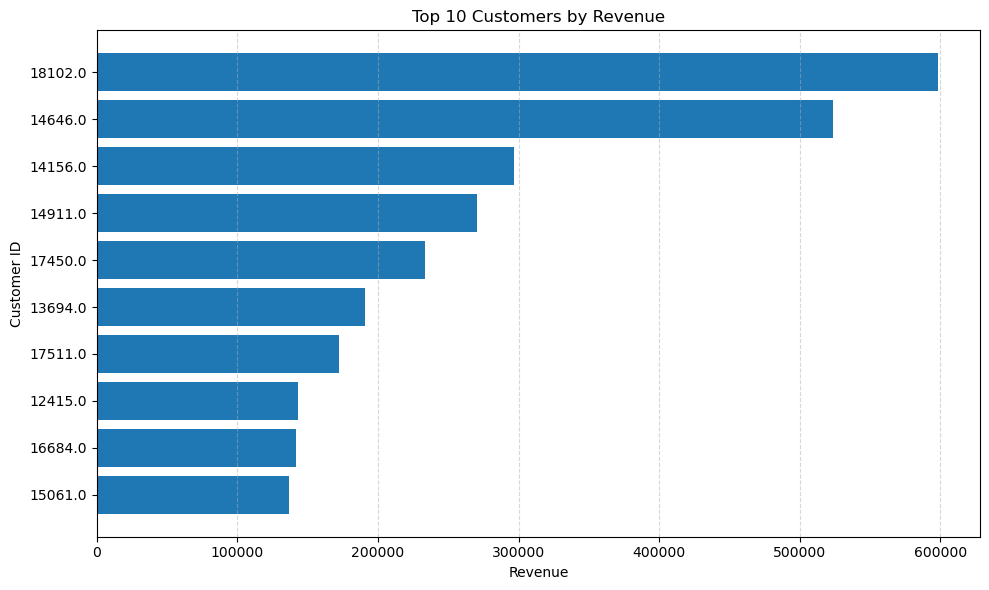

In [106]:
plt.figure(figsize=(10,6))

plt.barh(
    customer_revenue['Customer ID'].astype('str') ,
    customer_revenue['Revenue']
)

plt.title('Top 10 Customers by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Customer ID')
plt.gca().invert_yaxis()
plt.grid(axis='x' , linestyle = '--' , alpha=0.5)
plt.tight_layout()
plt.show()
    

In [118]:
customer_orders = (
    df.dropna(subset =['Customer ID'])
    .groupby('Customer ID')['Invoice']
             .nunique()
             .reset_index(name='Order_Count'))  

repeat_customer = customer_orders[
    customer_orders['Order_Count'] > 1
]

print('Repeat Customers:' ,  len(repeat_customer))

Repeat Customers: 4481


In [119]:
total_customers = len(customer_orders)

repeat_percentage = round(
    len(repeat_customer) / total_customers * 100 , 2 )

print(total_customers)
print(repeat_percentage)

5942
75.41


In [122]:
one_time_customer = (customer_orders['Order_Count'] == 1).sum()
one_time_customer

np.int64(1461)

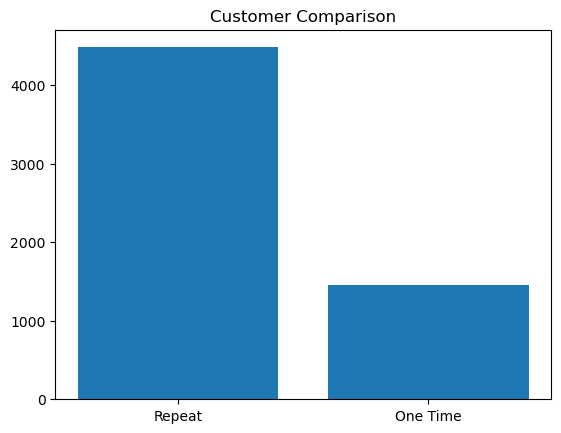

In [123]:
plt.bar(['Repeat' , 'One Time'] , [4481 , 1461])
plt.title('Customer Comparison')
plt.show()

In [124]:
df['Invoice'].astype(str).str.startswith('C').sum()

np.int64(19433)

In [125]:
(df['Quantity'] < 0).sum()

np.int64(22889)

In [126]:
df.loc[df['Quantity'] < 0 , 'Revenue'].sum()

np.float64(-1523788.38)

In [127]:
df.loc[df['Quantity'] > 0 , 'Revenue'].sum()

np.float64(20755588.898000002)

In [131]:
Average_Order_Value = total_revenue / unique_invoices
Average_Order_Value

np.float64(358.6149123219214)